==============================================================================
DA Mini Project - Statistical Analysis of NASA Confirmed Exoplanets
Data : nasa_exoplanet_intelligence.csv (6,150 planets x 31 columns)
Run  : python Exoplanet_Analysis_Final.py   (keep the CSV in the same folder)
       or open Exoplanet_Analysis_Final.ipynb in Jupyter / Colab

Methods used (all from the course): descriptive statistics, log transform, Pearson
correlation, Welch t-test, chi-square test, one-way ANOVA, two-way ANOVA,
multiple linear regression (R2 / RMSE / MAE), KMeans (elbow + silhouette) and PCA.
==============================================================================

# 1. Setup

In [5]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore", message=".*non-interactive.*")
CSV_PATH = "nasa_exoplanet_intelligence.csv"
FIG_DIR = "figures"
ALPHA = 0.05          # significance level for every hypothesis test
SEED = 42
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})


def finish(fig, name):
    """Save a figure to ./figures, show it (inline in Jupyter) and close it."""
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# 2. Load data and quality checks

In [6]:
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"Put {CSV_PATH} in the same folder as this script / notebook.")
raw = pd.read_csv(CSV_PATH)
print("Shape:", raw.shape, "| duplicate rows:", raw.duplicated().sum(),
      "| duplicate planet names:", raw.planet_name.duplicated().sum())

miss = (raw.isna().mean() * 100).sort_values(ascending=False)
print("\nMissing values (%):\n", miss[miss > 0].round(1).to_string())
print("Total missing cells:", int(raw.isna().sum().sum()))

print("\nSkewness before/after log10 and outliers (IQR rule):")
for c in ["planet_radius_earth", "planet_mass_earth", "orbital_period_days"]:
    s = raw[c].dropna()
    q1, q3 = s.quantile([.25, .75])
    fence = q3 + 1.5 * (q3 - q1)
    print(f"  {c:22s} skew {s.skew():6.2f} -> {np.log10(s[s > 0]).skew():5.2f} after log | "
          f"above IQR fence: {(s > fence).sum()} ({(s > fence).mean() * 100:.1f}%) | max = {s.max():g}")

print("\n'Unknown' planet_type:", (raw.planet_type == "Unknown").sum(),
      "| 'Unknown' star_type:", (raw.star_type == "Unknown").sum(),
      "| controversial planets:", int(raw.controversial_flag.sum()),
      "| missing disc_year:", int(raw.disc_year.isna().sum()))
print("Extreme orbital periods (> 1e6 days, directly imaged):", int((raw.orbital_period_days > 1e6).sum()))

Shape: (6150, 31) | duplicate rows: 0 | duplicate planet names: 0

Missing values (%):
 equilibrium_temp_k      25.4
star_age_gyr            21.3
orbital_eccentricity    15.3
star_metallicity         8.9
orbital_period_days      5.4
star_surface_gravity     5.2
semi_major_axis_au       5.1
star_radius_sun          5.1
star_vmag                4.8
star_temp_k              4.7
planet_radius_earth      0.8
planet_mass_earth        0.5
dist_from_earth_pc       0.4
star_mass_sun            0.1
disc_year                0.0
Total missing cells: 6346

Skewness before/after log10 and outliers (IQR rule):
  planet_radius_earth    skew   1.74 ->  0.26 after log | above IQR fence: 6 (0.1%) | max = 87.2059
  planet_mass_earth      skew   4.39 ->  0.66 after log | above IQR fence: 1009 (16.5%) | max = 9534.85
  orbital_period_days    skew  76.15 ->  1.36 after log | above IQR fence: 1014 (17.4%) | max = 4.02e+08

'Unknown' planet_type: 50 | 'Unknown' star_type: 290 | controversial planets: 49 | miss

# 3. Preprocessing and feature engineering
Missing values are **not** imputed for the analysis: temperature, period etc. are physical
measurements, so each test uses the rows where its variables exist. (In the earlier IA4 versions
of this code, median and regression imputation gave the same regression R2, so the extra complexity was dropped.)

### Separate regression estimates for missing temperatures

A linear regression uses host-star temperature, semi-major axis, and host-star radius to estimate equilibrium temperatures where the catalog value is missing and all three predictors are available. Estimates are stored in `predicted_equilibrium_temp_k`; the original `equilibrium_temp_k` values remain unchanged. The new column is included in `exoplanets_cleaned.csv`.


In [ ]:
df = raw.copy()
for c in ["planet_type", "star_type", "dist_category", "orbital_period_cat"]:
    df[c] = df[c].replace("Unknown", np.nan)

df["Era"] = np.where(df.disc_year < 2015, "Pre-2015", "2015+")
df.loc[df.disc_year.isna(), "Era"] = np.nan
df["Decade"] = df.disc_year // 10 * 10
df["Star_Class"] = df.star_type.str[0]                           # 'G-type(Sun-like)' -> 'G'
df["Star_Group"] = df.Star_Class.replace({"A": "Hot (A/B/O)", "B": "Hot (A/B/O)", "O": "Hot (A/B/O)"})
df["Planet_Group"] = np.select([df.planet_type.isin(["Gas Giant", "Super-Jupiter"]),
                                df.planet_type.isin(["Sub-Earth", "Super-Earth"])], ["Giant", "Rocky"], default="Other")
for col, new in [("planet_radius_earth", "log_radius"), ("planet_mass_earth", "log_mass"),
                 ("orbital_period_days", "log_period"), ("dist_from_earth_pc", "log_dist"),
                 ("equilibrium_temp_k", "log_teq"), ("star_mass_sun", "log_star_mass")]:
    df[new] = np.log10(df[col].where(df[col] > 0))

# --- physics columns for the habitable-zone analysis -------------------------------------
# luminosity (Sun = 1) from star radius and temperature
df["star_lum"] = df.star_radius_sun ** 2 * (df.star_temp_k / 5772.0) ** 4
# missing orbit sizes from Kepler's third law: a^3 = M * P^2  (P in years)
a_kepler = (df.star_mass_sun * (df.orbital_period_days / 365.25) ** 2) ** (1 / 3)
df["sma_au"] = df.semi_major_axis_au.fillna(a_kepler)
df["insolation"] = df.star_lum / df.sma_au ** 2                   # energy received (Earth = 1)

# Kopparapu et al. (2013) habitable-zone limits: S_eff = S0 + A*T + B*T^2 + C*T^3 + D*T^4, T = Teff - 5780
HZ_COEF = {"inner_opt": (1.7753, 1.4316e-4, 2.9875e-9, -7.5702e-12, -1.1635e-15),    # recent Venus
           "inner_con": (1.0140, 8.1774e-5, 1.7063e-9, -4.3241e-12, -6.6462e-16),    # moist greenhouse
           "outer_con": (0.3438, 5.8942e-5, 1.6558e-9, -3.0045e-12, -5.2983e-16),    # maximum greenhouse
           "outer_opt": (0.3179, 5.4513e-5, 1.5313e-9, -2.7786e-12, -4.8997e-16)}    # early Mars


def hz_limit(key, teff):
    s0, A, B, C, D = HZ_COEF[key]
    t = np.clip(teff, 2600, 7200) - 5780.0
    return np.sqrt(df.star_lum / (s0 + A * t + B * t ** 2 + C * t ** 3 + D * t ** 4))


valid_hz = df.star_temp_k.between(2500, 7500) & df.star_lum.notna() & df.sma_au.notna()
for key in HZ_COEF:
    df["hz_" + key] = np.where(valid_hz, hz_limit(key, df.star_temp_k), np.nan)
df["HZ_conservative"] = valid_hz & df.sma_au.between(df.hz_inner_con, df.hz_outer_con)
df["HZ_optimistic"] = valid_hz & df.sma_au.between(df.hz_inner_opt, df.hz_outer_opt)

# Earth Similarity Index (radius, density, escape velocity, temperature) - 1.0 means Earth
df["density"] = 5.51 * df.planet_mass_earth / df.planet_radius_earth ** 3
df["esc_vel"] = 11.19 * np.sqrt(df.planet_mass_earth / df.planet_radius_earth)


def esi_part(x, x0, w):
    return (1 - np.abs(x - x0) / (x + x0)) ** (w / 4)


df["ESI"] = (esi_part(df.planet_radius_earth, 1, .57) * esi_part(df.density / 5.51, 1, 1.07) *
             esi_part(df.esc_vel / 11.19, 1, .70) * esi_part(df.equilibrium_temp_k, 255, 5.58))
df.loc[(df.density > 25) | (df.density < 0.05), "ESI"] = np.nan   # physically impossible densities

# Predict missing equilibrium temperatures in a separate column.
# Observed equilibrium_temp_k values are copied unchanged.
temp_features = ["star_temp_k", "sma_au", "star_radius_sun"]
temp_target = "equilibrium_temp_k"
temp_training = df.dropna(subset=temp_features + [temp_target])
df["predicted_equilibrium_temp_k"] = df[temp_target]
temp_to_predict = df[temp_target].isna() & df[temp_features].notna().all(axis=1)
predicted_temp_count = 0
if not temp_training.empty and temp_to_predict.any():
    temp_model = LinearRegression().fit(temp_training[temp_features], temp_training[temp_target])
    df.loc[temp_to_predict, "predicted_equilibrium_temp_k"] = temp_model.predict(
        df.loc[temp_to_predict, temp_features]
    )
    predicted_temp_count = int(temp_to_predict.sum())
print(f"Missing equilibrium temperatures predicted: {predicted_temp_count}")

FGKM = ["F", "G", "K", "M"]
PT_ORDER = ["Sub-Earth", "Super-Earth", "Mini-Neptune", "Neptune-like", "Gas Giant", "Super-Jupiter"]
CLEAN_PATH = "exoplanets_cleaned.csv"
df.to_csv(CLEAN_PATH, index=False)
print("Cleaned dataset saved at:", os.path.abspath(CLEAN_PATH))
print(f"  {df.shape[0]} rows x {df.shape[1]} columns ({df.shape[1] - raw.shape[1]} new columns; original file untouched)")
try:                       # Google Colab only: also download the file to your computer
    from google.colab import files
    files.download(CLEAN_PATH)
except ImportError:
    pass

# 4. Exploratory data analysis

In [8]:
desc_cols = ["planet_radius_earth", "planet_mass_earth", "orbital_period_days", "equilibrium_temp_k",
             "star_temp_k", "star_mass_sun", "star_metallicity", "dist_from_earth_pc"]
print("Descriptive statistics:")
print(df[desc_cols].agg(["count", "mean", "median", "std", "min", "max"]).T.round(2).to_string())
print("\nDiscovery method (%):\n", (df.discovery_method.value_counts(normalize=True) * 100).round(1).head(4).to_string())
print("\nPlanet types:\n", df.planet_type.value_counts().reindex(PT_ORDER).to_string())
print("\nStar types:\n", df.star_type.value_counts(dropna=False).to_string())
per_year = df.groupby("disc_year").size()
print("\nPeak discovery year:", int(per_year.idxmax()), "with", int(per_year.max()), "planets",
      "| 2026 is a partial year:", int(per_year.loc[2026]), "planets")
print("Multi-planet systems:", round(df.multi_planet_system.mean() * 100, 1), "%")
mr = df[["log_mass", "log_radius"]].dropna()
r_mr = stats.pearsonr(mr.log_mass, mr.log_radius)[0]
print(f"log mass vs log radius: n = {len(mr)}, Pearson r = {r_mr:.3f}")

Descriptive statistics:
                      count      mean   median         std     min           max
planet_radius_earth  6100.0      5.84     2.84        5.44    0.31  8.721000e+01
planet_mass_earth    6119.0    406.79     9.27     1142.87    0.02  9.534850e+03
orbital_period_days  5816.0  73594.21    11.13  5273718.15    0.09  4.020000e+08
equilibrium_temp_k   4587.0    912.90   818.00      464.27   34.00  4.050000e+03
star_temp_k          5860.0   5398.16  5546.00     1747.46  415.00  5.700000e+04
star_mass_sun        6142.0      0.94     0.94        0.41    0.01  1.094000e+01
star_metallicity     5600.0      0.02     0.02        0.19   -1.00  6.000000e-01
dist_from_earth_pc   6123.0    711.67   376.66     1212.14    1.30  8.500000e+03

Discovery method (%):
 discovery_method
Transit            73.4
Radial Velocity    19.2
Microlensing        4.5
Imaging             1.5

Planet types:
 planet_type
Sub-Earth         230
Super-Earth      1185
Mini-Neptune     2148
Neptune-like    

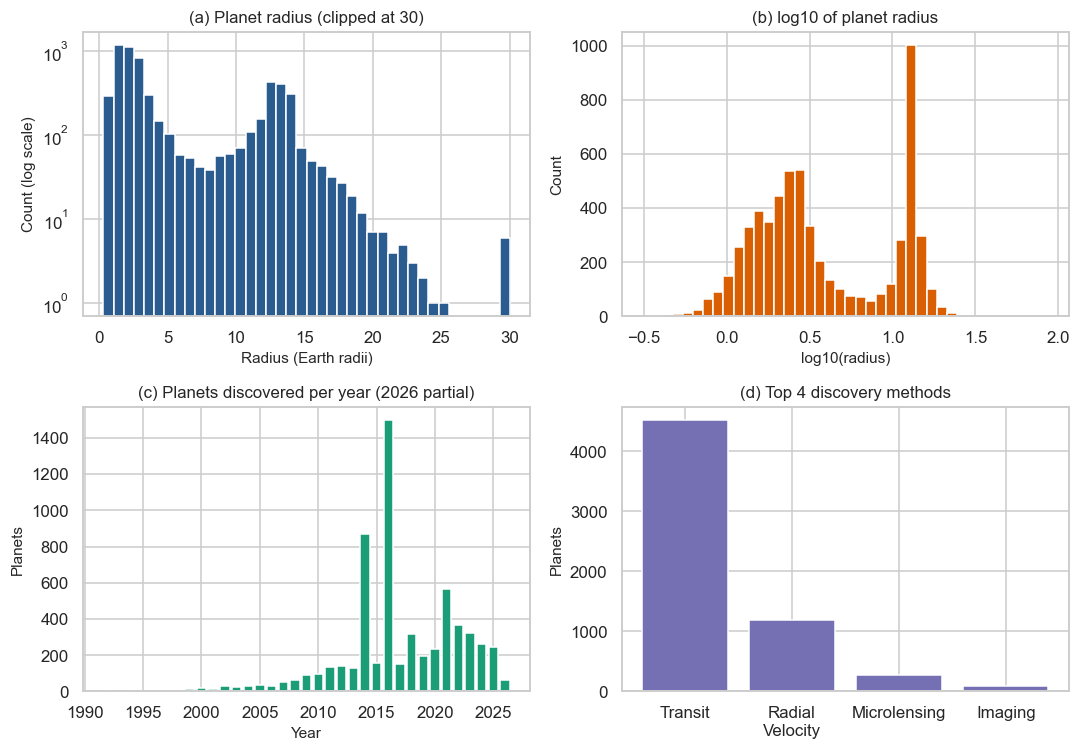

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
ax[0, 0].hist(df.planet_radius_earth.dropna().clip(upper=30), bins=40, color="#2b5c8f", edgecolor="white")
ax[0, 0].set_yscale("log"); ax[0, 0].set_title("(a) Planet radius (clipped at 30)")
ax[0, 0].set_xlabel("Radius (Earth radii)"); ax[0, 0].set_ylabel("Count (log scale)")
ax[0, 1].hist(df.log_radius.dropna(), bins=40, color="#d95f02", edgecolor="white")
ax[0, 1].set_title("(b) log10 of planet radius"); ax[0, 1].set_xlabel("log10(radius)"); ax[0, 1].set_ylabel("Count")
ax[1, 0].bar(per_year.index, per_year.values, color="#1b9e77")
ax[1, 0].set_title("(c) Planets discovered per year (2026 partial)"); ax[1, 0].set_xlabel("Year"); ax[1, 0].set_ylabel("Planets")
top = df.discovery_method.value_counts().head(4)
ax[1, 1].bar(top.index.str.replace(" ", "\n"), top.values, color="#7570b3")
ax[1, 1].set_title("(d) Top 4 discovery methods"); ax[1, 1].set_ylabel("Planets")
finish(fig, "fig1_univariate")

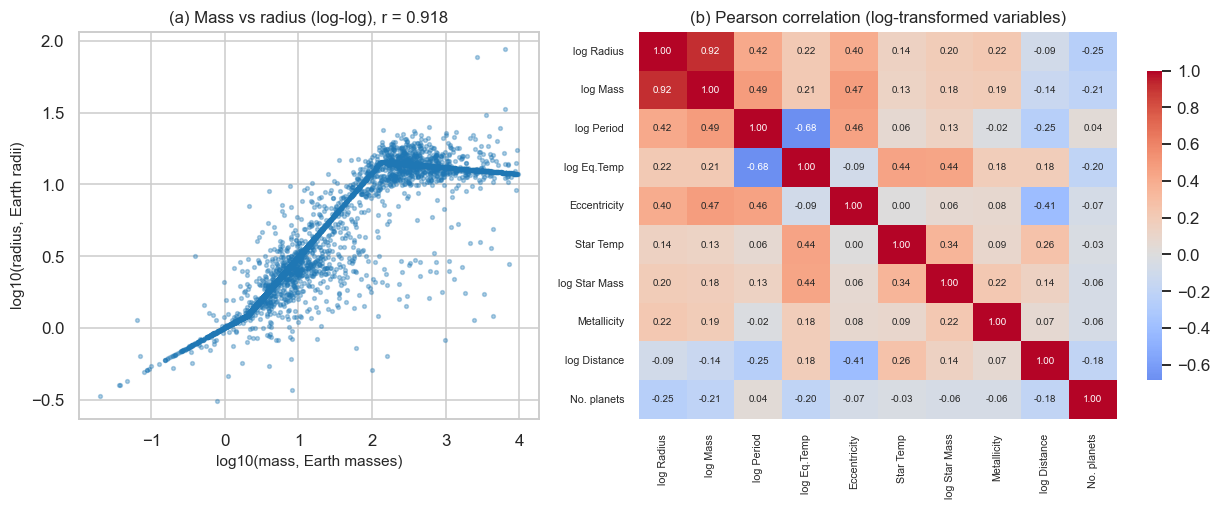

In [10]:
corr_cols = ["log_radius", "log_mass", "log_period", "log_teq", "orbital_eccentricity", "star_temp_k",
             "log_star_mass", "star_metallicity", "log_dist", "n_planets"]
corr_names = ["log Radius", "log Mass", "log Period", "log Eq.Temp", "Eccentricity", "Star Temp",
              "log Star Mass", "Metallicity", "log Distance", "No. planets"]
cm = df[corr_cols].corr()
cm.index, cm.columns = corr_names, corr_names
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].scatter(df.log_mass, df.log_radius, s=6, alpha=.35, color="#1f77b4")
ax[0].set_xlabel("log10(mass, Earth masses)"); ax[0].set_ylabel("log10(radius, Earth radii)")
ax[0].set_title(f"(a) Mass vs radius (log-log), r = {r_mr:.3f}")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 6.5}, cbar_kws={"shrink": .8}, ax=ax[1])
ax[1].set_title("(b) Pearson correlation (log-transformed variables)"); ax[1].tick_params(labelsize=7)
finish(fig, "fig2_mass_radius_correlation")

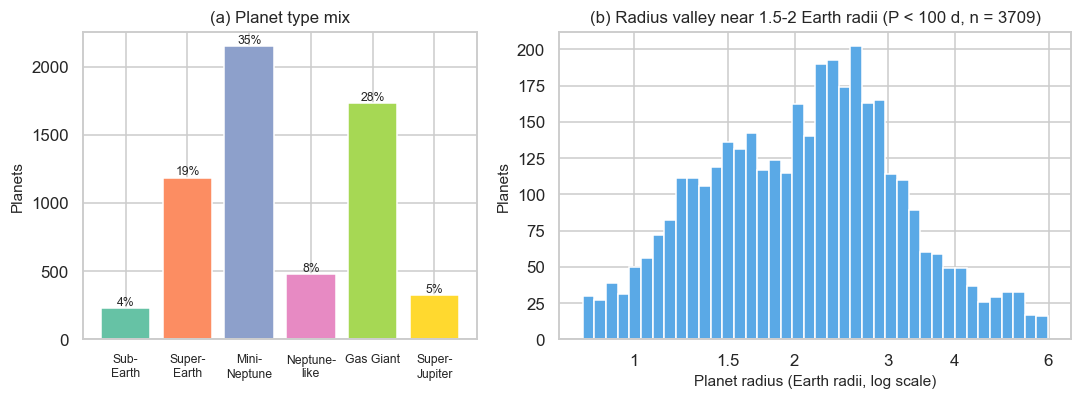

In [11]:
sp = df[(df.orbital_period_days < 100) & df.planet_radius_earth.between(0.8, 6)]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
pt = df.planet_type.value_counts().reindex(PT_ORDER)
ax[0].bar(range(6), pt.values, color=sns.color_palette("Set2", 6))
ax[0].set_xticks(range(6)); ax[0].set_xticklabels([p.replace("-", "-\n") for p in PT_ORDER], fontsize=8)
for i, v in enumerate(pt.values):
    ax[0].text(i, v + 20, f"{v / pt.sum() * 100:.0f}%", ha="center", fontsize=8)
ax[0].set_title("(a) Planet type mix"); ax[0].set_ylabel("Planets")
ax[1].hist(np.log10(sp.planet_radius_earth), bins=40, color="#5aa9e6", edgecolor="white")
ax[1].set_xticks(np.log10([1, 1.5, 2, 3, 4, 6])); ax[1].set_xticklabels(["1", "1.5", "2", "3", "4", "6"])
ax[1].set_xlabel("Planet radius (Earth radii, log scale)"); ax[1].set_ylabel("Planets")
ax[1].set_title(f"(b) Radius valley near 1.5-2 Earth radii (P < 100 d, n = {len(sp)})")
finish(fig, "fig3_planet_types_radius_valley")

# 5. Star-type grouping and temperatures

In [12]:
grp = df[df.Star_Group.notna()].groupby("Star_Group")
star_tab = grp.agg(planets=("planet_name", "count"), host_stars=("host_star", "nunique"),
                   med_star_temp_K=("star_temp_k", "median"), med_planet_radius=("planet_radius_earth", "median"),
                   med_period_days=("orbital_period_days", "median"), med_planet_Teq_K=("equilibrium_temp_k", "median"),
                   med_distance_pc=("dist_from_earth_pc", "median"))
star_tab["planets_per_host"] = (star_tab.planets / star_tab.host_stars).round(2)
star_tab["pct_small_planets(<2R)"] = (grp.apply(lambda g: (g.planet_radius_earth < 2).sum() / g.planet_radius_earth.notna().sum()) * 100).round(1)
star_tab = star_tab.reindex(["M", "K", "G", "F", "Hot (A/B/O)"]).round(1)
print("Planets grouped by host-star type:\n", star_tab.to_string())
print("\nHost stars below 0.075 solar masses (brown-dwarf hosts, kept in the M group):", int((df.star_mass_sun < 0.075).sum()))

ct_pt = pd.crosstab(df.Star_Class, df.planet_type).reindex(index=FGKM, columns=PT_ORDER)
print("\nPlanet-type mix by star type (% of planets):\n", (ct_pt.div(ct_pt.sum(axis=1), axis=0) * 100).round(1).to_string())
r_t = df[["star_temp_k", "log_teq"]].dropna().corr().iloc[0, 1]
print(f"\nPearson r (star temperature, log planet Teq) = {r_t:.2f}")
print("Median planet Teq by star type (K):", df[df.Star_Class.isin(FGKM)].groupby("Star_Class").equilibrium_temp_k.median().reindex(FGKM).round(0).to_dict())

Planets grouped by host-star type:
              planets  host_stars  med_star_temp_K  med_planet_radius  med_period_days  med_planet_Teq_K  med_distance_pc  planets_per_host  pct_small_planets(<2R)
Star_Group                                                                                                                                                        
M                423         290           3413.0                1.9              6.5             471.0             30.5               1.5                    52.1
K               1644        1195           4779.5                2.6             11.7             666.0            197.2               1.4                    32.7
G               2669        1958           5670.0                2.8             12.1             859.8            504.7               1.4                    27.4
F               1075         845           6174.0                3.4             10.3            1108.0            604.0               1.3           

C:\Users\JSNV_C\AppData\Local\Temp\ipykernel_4388\2237776644.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  star_tab["pct_small_planets(<2R)"] = (grp.apply(lambda g: (g.planet_radius_earth < 2).sum() / g.planet_radius_earth.notna().sum()) * 100).round(1)


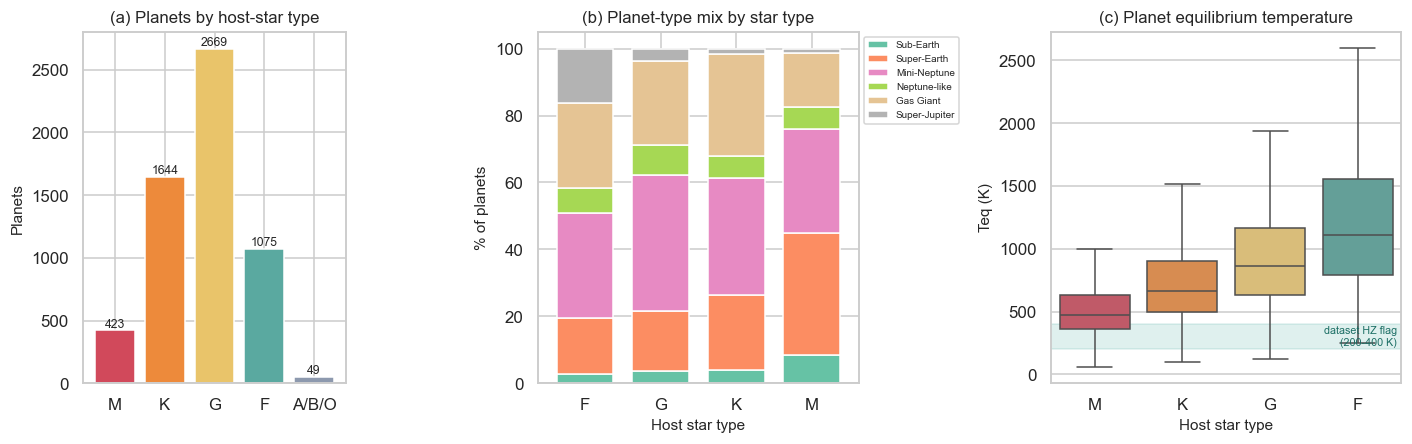

In [13]:
col = {"M": "#d1495b", "K": "#ed8a3b", "G": "#e9c46a", "F": "#5aa9a0"}
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [0.9, 1.1, 1.2]})
sg = star_tab.reindex(["M", "K", "G", "F", "Hot (A/B/O)"])
ax[0].bar(range(5), sg.planets, color=[col.get(k, "#8d99ae") for k in sg.index])
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(["M", "K", "G", "F", "A/B/O"])
for i, v in enumerate(sg.planets):
    ax[0].text(i, v + 25, int(v), ha="center", fontsize=8)
ax[0].set_title("(a) Planets by host-star type"); ax[0].set_ylabel("Planets")
(ct_pt.div(ct_pt.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, ax=ax[1], colormap="Set2", width=.75)
ax[1].set_title("(b) Planet-type mix by star type"); ax[1].set_xlabel("Host star type"); ax[1].set_ylabel("% of planets")
ax[1].tick_params(axis="x", rotation=0); ax[1].legend(fontsize=6.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
bx = df[df.Star_Class.isin(FGKM)]
sns.boxplot(data=bx, x="Star_Class", y="equilibrium_temp_k", order=["M", "K", "G", "F"], hue="Star_Class",
            palette=col, legend=False, showfliers=False, ax=ax[2])
ax[2].axhspan(200, 400, color="#2a9d8f", alpha=.15)
ax[2].text(3.45, 300, "dataset HZ flag\n(200-400 K)", fontsize=7, ha="right", va="center", color="#1b6e64")
ax[2].set_title("(c) Planet equilibrium temperature"); ax[2].set_xlabel("Host star type"); ax[2].set_ylabel("Teq (K)")
finish(fig, "fig4_star_types_temperature")

# 6. Habitable zones and Earth-like candidates
The dataset's own `habitable_zone_flag` is checked against a flux-based habitable zone computed
from each star's luminosity.

In [14]:
rule = df.equilibrium_temp_k.between(200, 400)
print("Dataset flag equals 'Teq between 200 and 400 K' for every planet:", bool((rule == df.habitable_zone_flag).all()),
      "| flagged planets:", int(df.habitable_zone_flag.sum()))
v = df[valid_hz]
print(f"\nFlux-based HZ evaluated for {len(v)} planets: conservative = {int(v.HZ_conservative.sum())}, optimistic = {int(v.HZ_optimistic.sum())}")
agree = pd.crosstab(v.habitable_zone_flag.map({True: "Dataset flag: HZ", False: "Dataset flag: not HZ"}),
                    v.HZ_optimistic.map({True: "Flux HZ (optimistic)", False: "Not in flux HZ"}))
print("\nDataset flag vs flux-based HZ:\n", agree.to_string())
hot = (v.habitable_zone_flag & (v.sma_au < v.hz_inner_opt)).sum()
print(f"Flagged by the dataset but too hot by the flux definition: {int(hot)}")

hz_star = pd.DataFrame({"planets": v.groupby("Star_Class").size(), "dataset_flag": v.groupby("Star_Class").habitable_zone_flag.sum(),
                        "flux_optimistic": v.groupby("Star_Class").HZ_optimistic.sum(),
                        "flux_conservative": v.groupby("Star_Class").HZ_conservative.sum()}).reindex(FGKM)
hz_star["pct_in_optimistic_HZ"] = (hz_star.flux_optimistic / hz_star.planets * 100).round(1)
print("\nHabitable-zone planets by star type:\n", hz_star.to_string())
small = v[v.planet_radius_earth.between(0.5, 2.0) & v.Star_Class.isin(FGKM)]
small_rate = small.groupby("Star_Class").HZ_optimistic.agg(["sum", "count"]).reindex(FGKM)
small_rate["pct"] = (small_rate["sum"] / small_rate["count"] * 100).round(1)
print("\nSmall planets (0.5-2 Earth radii) inside the optimistic HZ:\n", small_rate.to_string())

cand = df[df.HZ_optimistic & df.planet_radius_earth.between(0.5, 2.0) & (df.controversial_flag == 0)].sort_values("ESI", ascending=False)
print(f"\nCandidates (0.5-2 Earth radii, optimistic HZ, not controversial): {len(cand)}")
print(cand[["planet_name", "star_type", "planet_radius_earth", "insolation", "equilibrium_temp_k", "ESI", "dist_from_earth_pc"]]
      .head(15).round(2).to_string(index=False))

Dataset flag equals 'Teq between 200 and 400 K' for every planet: True | flagged planets: 403

Flux-based HZ evaluated for 5788 planets: conservative = 172, optimistic = 294

Dataset flag vs flux-based HZ:
 HZ_optimistic         Flux HZ (optimistic)  Not in flux HZ
habitable_zone_flag                                       
Dataset flag: HZ                       109             291
Dataset flag: not HZ                   185            5203
Flagged by the dataset but too hot by the flux definition: 286

Habitable-zone planets by star type:
             planets  dataset_flag  flux_optimistic  flux_conservative  pct_in_optimistic_HZ
Star_Class                                                                                 
F              1075            26               28                 20                   2.6
G              2662           127              122                 76                   4.6
K              1641           152               89                 49                  

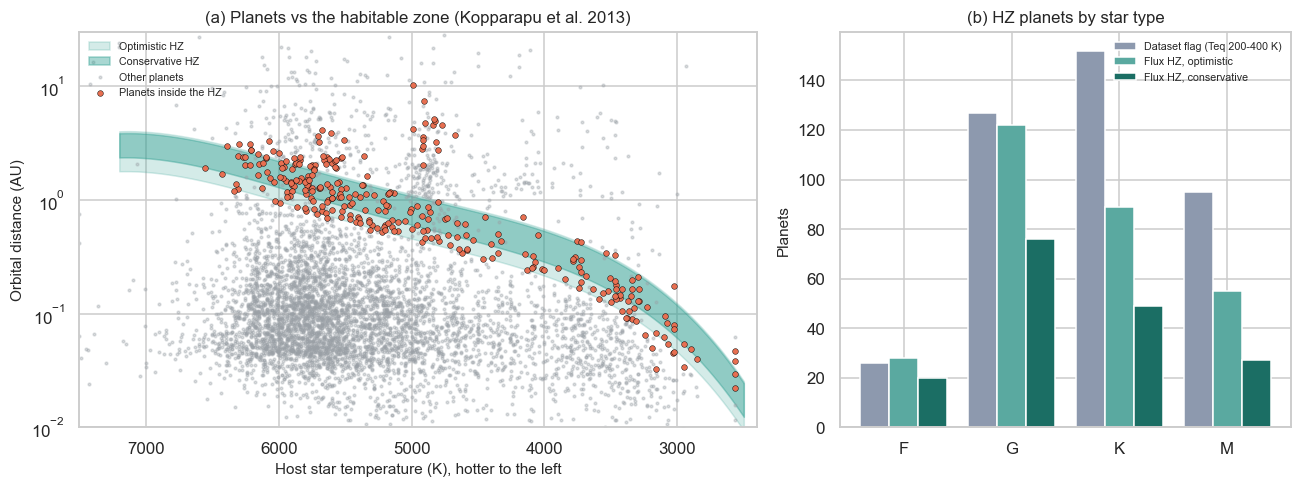

In [15]:
dd = df.dropna(subset=["star_temp_k", "star_lum"])
dd = dd[dd.star_temp_k.between(2500, 7200) & (dd.star_radius_sun < 2) & (dd.star_lum > 0)]
poly = np.polyfit(dd.star_temp_k / 1000, np.log10(dd.star_lum), 4)       # typical luminosity at each temperature
tt = np.linspace(2500, 7200, 120)
L_t = 10 ** np.polyval(poly, tt / 1000)


def band(key):
    s0, A, B, C, D = HZ_COEF[key]
    t = np.clip(tt, 2600, 7200) - 5780.0
    return np.sqrt(L_t / (s0 + A * t + B * t ** 2 + C * t ** 3 + D * t ** 4))


fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].fill_between(tt, band("inner_opt"), band("outer_opt"), color="#2a9d8f", alpha=.2, label="Optimistic HZ")
ax[0].fill_between(tt, band("inner_con"), band("outer_con"), color="#2a9d8f", alpha=.4, label="Conservative HZ")
o = df[~df.HZ_optimistic & df.star_temp_k.between(2400, 7500) & df.sma_au.notna()]
ax[0].scatter(o.star_temp_k, o.sma_au, s=3, color="#9aa0a6", alpha=.35, label="Other planets")
h = df[df.HZ_optimistic]
ax[0].scatter(h.star_temp_k, h.sma_au, s=14, color="#e76f51", edgecolor="black", linewidth=.3, label="Planets inside the HZ")
ax[0].set_yscale("log"); ax[0].set_ylim(0.01, 30); ax[0].set_xlim(7500, 2400)
ax[0].set_xlabel("Host star temperature (K), hotter to the left"); ax[0].set_ylabel("Orbital distance (AU)")
ax[0].set_title("(a) Planets vs the habitable zone (Kopparapu et al. 2013)"); ax[0].legend(fontsize=7, frameon=False, loc="upper left")
x = np.arange(4); w = .27
ax[1].bar(x - w, hz_star.dataset_flag, w, color="#8d99ae", label="Dataset flag (Teq 200-400 K)")
ax[1].bar(x, hz_star.flux_optimistic, w, color="#5aa9a0", label="Flux HZ, optimistic")
ax[1].bar(x + w, hz_star.flux_conservative, w, color="#1b6e64", label="Flux HZ, conservative")
ax[1].set_xticks(x); ax[1].set_xticklabels(FGKM); ax[1].legend(fontsize=7, frameon=False)
ax[1].set_title("(b) HZ planets by star type"); ax[1].set_ylabel("Planets")
finish(fig, "fig5_habitable_zones")

# 7. Hypothesis testing (alpha = 0.05)
Rule: reject H0 when p < 0.05. Skewed variables (radius) are log-transformed first.

In [16]:
def welch(a, b):
    """Welch's independent t-test (does not assume equal variances). Returns t, df, p."""
    t, p = stats.ttest_ind(a, b, equal_var=False)
    n1, n2, v1, v2 = len(a), len(b), a.var(), b.var()
    dfw = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    return t, dfw, p


def chi_square(table):
    chi2, p, dof, exp = stats.chi2_contingency(table)
    return chi2, p, dof, exp.min()


def decision(p):
    return "reject H0" if p < ALPHA else "fail to reject H0"


def core_tests(data):
    """H1-H4 on any subset of the data (used again for the sensitivity check)."""
    out = {}
    sub = data[data.Star_Class.isin(FGKM) & data.planet_type.notna()]
    out["H1"] = chi_square(pd.crosstab(sub.Star_Class, sub.planet_type).reindex(index=FGKM, columns=PT_ORDER))[1]
    g = data.loc[data.Planet_Group == "Giant", "star_metallicity"].dropna()
    r = data.loc[data.Planet_Group == "Rocky", "star_metallicity"].dropna()
    out["H2"] = welch(g, r)[2]
    out["H3"] = stats.f_oneway(*[data.loc[data.Star_Class == s, "log_radius"].dropna() for s in FGKM])[1]
    out["H4"] = welch(data.loc[data.Era == "Pre-2015", "log_radius"].dropna(), data.loc[data.Era == "2015+", "log_radius"].dropna())[2]
    return out


# --- H1 chi-square: does the planet-type mix depend on the host-star type?
sub = df[df.Star_Class.isin(FGKM) & df.planet_type.notna()]
ct1 = pd.crosstab(sub.Star_Class, sub.planet_type).reindex(index=FGKM, columns=PT_ORDER)
chi2, p1, dof, emin = chi_square(ct1)
print("H1  H0: planet type is independent of host-star type (F, G, K, M)")
print(f"    chi2({dof}) = {chi2:.1f}, p = {p1:.2e}, n = {ct1.values.sum()}, smallest expected count = {emin:.1f} (>5, valid) -> {decision(p1)}")

# --- H2 Welch t-test: host metallicity, giants vs rocky planets
g = df.loc[df.Planet_Group == "Giant", "star_metallicity"].dropna()
r = df.loc[df.Planet_Group == "Rocky", "star_metallicity"].dropna()
t2, df2, p2 = welch(g, r)
print("\nH2  H0: mean host-star metallicity is equal for giant and rocky planets")
print(f"    t({df2:.0f}) = {t2:.2f}, p = {p2:.2e} | mean [Fe/H] giants = {g.mean():.3f} (n={len(g)}), rocky = {r.mean():.3f} (n={len(r)}) -> {decision(p2)}")

# --- H3 one-way ANOVA: log radius across F, G, K, M
groups3 = [df.loc[df.Star_Class == s, "log_radius"].dropna() for s in FGKM]
F3, p3 = stats.f_oneway(*groups3)
print("\nH3  H0: mean log10(planet radius) is the same for F, G, K and M host stars")
print(f"    F({len(groups3) - 1}, {sum(len(x) for x in groups3) - len(groups3)}) = {F3:.2f}, p = {p3:.2e} -> {decision(p3)}")
print("    group means of log10(radius):", [round(float(x.mean()), 3) for x in groups3], "| group std:", [round(float(x.std()), 3) for x in groups3],
      "| n:", [len(x) for x in groups3])
print("    median radius (Earth radii):", [round(float(df.loc[df.Star_Class == s, 'planet_radius_earth'].median()), 2) for s in FGKM])
print("    (similar group standard deviations -> the equal-variance assumption of ANOVA is reasonable)")

# --- H4 Welch t-test: log radius, discovered before 2015 vs 2015 onwards
pre = df.loc[df.Era == "Pre-2015", "log_radius"].dropna()
post = df.loc[df.Era == "2015+", "log_radius"].dropna()
t4, df4, p4 = welch(pre, post)
print("\nH4  H0: mean log10(planet radius) is the same before 2015 and from 2015 onwards")
print(f"    t({df4:.0f}) = {t4:.2f}, p = {p4:.2e} | geometric mean radius {10 ** pre.mean():.2f} vs {10 ** post.mean():.2f} Earth radii "
      f"(n = {len(pre)} vs {len(post)}) -> {decision(p4)}")

# --- H5 chi-square: is being inside the flux-based HZ related to star type?
sub5 = df[valid_hz & df.Star_Class.isin(FGKM)]
ct5 = pd.crosstab(sub5.Star_Class, sub5.HZ_optimistic).reindex(FGKM)
chi5, p5, dof5, emin5 = chi_square(ct5)
print("\nH5  H0: being inside the habitable zone is independent of host-star type")
print(f"    chi2({dof5}) = {chi5:.1f}, p = {p5:.2e}, smallest expected count = {emin5:.1f} -> {decision(p5)}")
print("    % of planets inside the optimistic HZ:", (ct5[True] / ct5.sum(axis=1) * 100).round(1).to_dict())


# --- H6 two-way ANOVA: log radius ~ star type x discovery era (with interaction)
def two_way_anova(y, a, b):
    """Type II two-way ANOVA with interaction, built from regression sums of squares."""
    y = np.asarray(y, float)
    A = pd.get_dummies(a, drop_first=True).astype(float).values
    B = pd.get_dummies(b, drop_first=True).astype(float).values
    AB = np.column_stack([A[:, i] * B[:, j] for i in range(A.shape[1]) for j in range(B.shape[1])])

    def ols(X):
        Xb = np.column_stack([np.ones(len(y)), X])
        beta = np.linalg.lstsq(Xb, y, rcond=None)[0]
        fit = Xb @ beta
        return np.sum((fit - y.mean()) ** 2), np.sum((y - fit) ** 2)

    ssA, _ = ols(A); ssB, _ = ols(B)
    ssMain, _ = ols(np.column_stack([A, B]))
    ssFull, rssFull = ols(np.column_stack([A, B, AB]))
    dfA, dfB = A.shape[1], B.shape[1]
    dfAB = dfA * dfB
    dfE = len(y) - (1 + dfA + dfB + dfAB)
    mse = rssFull / dfE
    res = {}
    for name, ss, d in [("Star type", ssMain - ssB, dfA), ("Era", ssMain - ssA, dfB), ("Star type x Era", ssFull - ssMain, dfAB)]:
        F = (ss / d) / mse
        res[name] = (F, d, dfE, stats.f.sf(F, d, dfE))
    return res


tw = df[df.Star_Class.isin(FGKM)].dropna(subset=["log_radius", "Era"])
aov2 = two_way_anova(tw.log_radius, tw.Star_Class, tw.Era)
print("\nH6  Two-way ANOVA on log10(radius): star type x discovery era (n = %d)" % len(tw))
print("    H0: no effect of star type, no effect of era, no interaction")
for k, (F, d1, d2, p) in aov2.items():
    print(f"    {k:16s} F({d1}, {d2}) = {F:7.2f}, p = {p:.2e} -> {decision(p)}")

# --- sensitivity: repeat H1-H4 without the controversial planets
base_p, nc_p = core_tests(df), core_tests(df[df.controversial_flag == 0])
print("\nSensitivity check - p-values with all planets vs without the controversial ones:")
for k in base_p:
    print(f"    {k}: {base_p[k]:.2e} vs {nc_p[k]:.2e}  (same decision: {(base_p[k] < ALPHA) == (nc_p[k] < ALPHA)})")

H1  H0: planet type is independent of host-star type (F, G, K, M)
    chi2(15) = 482.9, p = 2.37e-93, n = 5765, smallest expected count = 16.6 (>5, valid) -> reject H0

H2  H0: mean host-star metallicity is equal for giant and rocky planets
    t(3074) = 14.37, p = 2.24e-45 | mean [Fe/H] giants = 0.071 (n=1733), rocky = -0.028 (n=1356) -> reject H0

H3  H0: mean log10(planet radius) is the same for F, G, K and M host stars
    F(3, 5761) = 58.44, p = 3.30e-37 -> reject H0
    group means of log10(radius): [0.667, 0.553, 0.546, 0.374] | group std: [0.425, 0.378, 0.405, 0.377] | n: [1073, 2653, 1617, 422]
    median radius (Earth radii): [3.4, 2.8, 2.58, 1.9]
    (similar group standard deviations -> the equal-variance assumption of ANOVA is reasonable)

H4  H0: mean log10(planet radius) is the same before 2015 and from 2015 onwards
    t(3030) = 9.44, p = 7.01e-21 | geometric mean radius 4.56 vs 3.53 Earth radii (n = 1752 vs 4347) -> reject H0

H5  H0: being inside the habitable zone is

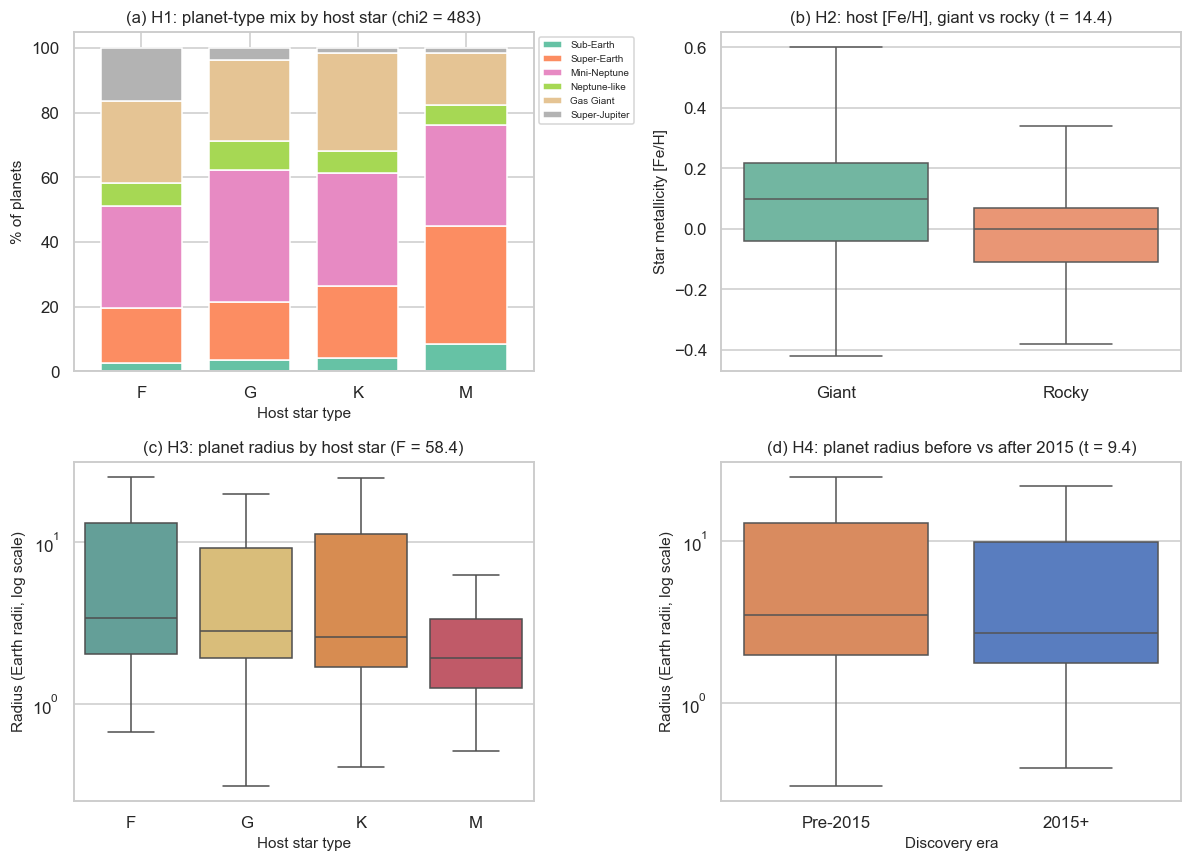

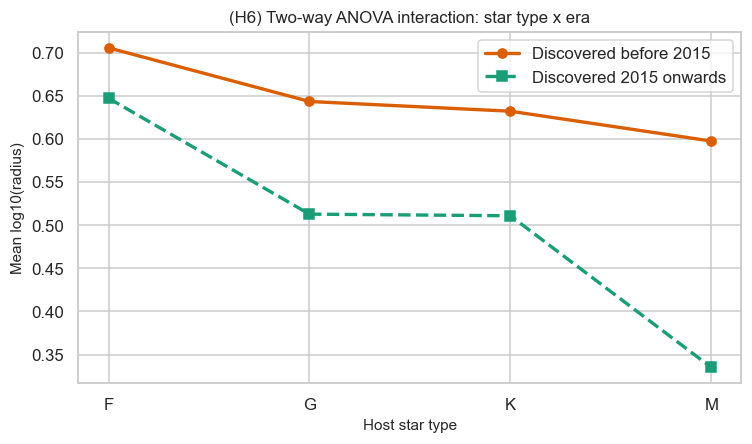

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ct1n = ct1.div(ct1.sum(axis=1), axis=0) * 100
ct1n.plot(kind="bar", stacked=True, ax=ax[0, 0], colormap="Set2", width=.75)
ax[0, 0].set_title(f"(a) H1: planet-type mix by host star (chi2 = {chi2:.0f})"); ax[0, 0].set_xlabel("Host star type")
ax[0, 0].set_ylabel("% of planets"); ax[0, 0].tick_params(axis="x", rotation=0); ax[0, 0].legend(fontsize=6.5, bbox_to_anchor=(1, 1), loc="upper left")
mt = pd.DataFrame({"Metallicity": pd.concat([g, r]), "Group": ["Giant"] * len(g) + ["Rocky"] * len(r)})
sns.boxplot(data=mt, x="Group", y="Metallicity", hue="Group", palette="Set2", legend=False, showfliers=False, ax=ax[0, 1])
ax[0, 1].set_title(f"(b) H2: host [Fe/H], giant vs rocky (t = {t2:.1f})"); ax[0, 1].set_ylabel("Star metallicity [Fe/H]"); ax[0, 1].set_xlabel("")
sns.boxplot(data=df[df.Star_Class.isin(FGKM)], x="Star_Class", y="planet_radius_earth", order=FGKM, hue="Star_Class",
            palette=col, legend=False, showfliers=False, ax=ax[1, 0])
ax[1, 0].set_yscale("log"); ax[1, 0].set_title(f"(c) H3: planet radius by host star (F = {F3:.1f})")
ax[1, 0].set_xlabel("Host star type"); ax[1, 0].set_ylabel("Radius (Earth radii, log scale)")
sns.boxplot(data=df.dropna(subset=["Era", "log_radius"]), x="Era", y="planet_radius_earth", order=["Pre-2015", "2015+"], hue="Era",
            palette="muted", legend=False, showfliers=False, ax=ax[1, 1])
ax[1, 1].set_yscale("log"); ax[1, 1].set_title(f"(d) H4: planet radius before vs after 2015 (t = {t4:.1f})")
ax[1, 1].set_xlabel("Discovery era"); ax[1, 1].set_ylabel("Radius (Earth radii, log scale)")
finish(fig, "fig6_hypothesis_tests")

fig, ax = plt.subplots(figsize=(7, 4.2))
means = tw.groupby(["Star_Class", "Era"]).log_radius.mean().unstack().reindex(FGKM)
ax.plot(FGKM, means["Pre-2015"], "o-", lw=2.2, color="#d95f02", label="Discovered before 2015")
ax.plot(FGKM, means["2015+"], "s--", lw=2.2, color="#1b9e77", label="Discovered 2015 onwards")
ax.set_xlabel("Host star type"); ax.set_ylabel("Mean log10(radius)")
ax.set_title("(H6) Two-way ANOVA interaction: star type x era"); ax.legend()
finish(fig, "fig7_two_way_anova")

# 8. Multiple linear regression: predicting log10(planet radius)
Model A uses planet mass (the mass-radius relation). Model B leaves mass out and asks how much
the orbit and host star alone explain. Rows with a missing value are dropped (no imputation, so
nothing from the test set leaks into training) and the 50 planets with no radius are excluded.

In [18]:
reg = df.dropna(subset=["log_radius"]).copy()
reg["Method_grp"] = reg.discovery_method.where(reg.discovery_method.isin(["Transit", "Radial Velocity", "Microlensing"]), "Other")
reg["Star_Group"] = reg.Star_Group.fillna("Unknown")
phys = ["log_period", "star_temp_k", "log_star_mass", "star_metallicity", "log_dist"]
need = phys + ["log_mass"]
n_before = len(reg)
reg = reg.dropna(subset=need)
print(f"Regression rows: {len(reg)} of {n_before} planets with a radius ({n_before - len(reg)} dropped for missing predictors, "
      f"mostly microlensing planets that have no orbital period)")
dummies = pd.get_dummies(reg[["Star_Group", "Method_grp"]], drop_first=True).astype(float)
X_all = pd.concat([reg[need], dummies], axis=1)
y_all = reg.log_radius
tr_idx, te_idx = train_test_split(X_all.index, test_size=0.2, random_state=SEED)


def fit_model(cols, label):
    Xtr, Xte, ytr, yte = X_all.loc[tr_idx, cols], X_all.loc[te_idx, cols], y_all.loc[tr_idx], y_all.loc[te_idx]
    sc = StandardScaler().fit(Xtr)
    m = LinearRegression().fit(sc.transform(Xtr), ytr)
    pred = m.predict(sc.transform(Xte))
    rmse = np.sqrt(mean_squared_error(yte, pred))
    res = dict(label=label, r2=r2_score(yte, pred), rmse=rmse, mae=mean_absolute_error(yte, pred),
               coef=pd.Series(m.coef_, index=cols), yte=yte, pred=pred)
    print(f"{label}: R2 = {res['r2']:.3f} | RMSE = {rmse:.3f} (about x{10 ** rmse:.2f} in radius) | MAE = {res['mae']:.3f} "
          f"| train {len(Xtr)} / test {len(Xte)}")
    return res


cols_B = [c for c in X_all.columns if c != "log_mass"]
resA = fit_model(list(X_all.columns), "Model A (with mass)   ")
resB = fit_model(cols_B, "Model B (without mass)")
print("\nStandardised coefficients, Model A (effect of +1 standard deviation on log10 radius):")
print(resA["coef"].sort_values(key=np.abs, ascending=False).round(3).head(8).to_string())
print("\nStandardised coefficients, Model B:")
print(resB["coef"].sort_values(key=np.abs, ascending=False).round(3).head(8).to_string())
print(f"\nReading: mass alone lifts R2 from {resB['r2']:.2f} to {resA['r2']:.2f}, so Model A mostly re-states the mass-radius law. "
      "Mass is present for 99.5% of planets, which suggests many values are model estimates from radius - check the column source.")

Regression rows: 5494 of 6100 planets with a radius (606 dropped for missing predictors, mostly microlensing planets that have no orbital period)
Model A (with mass)   : R2 = 0.844 | RMSE = 0.155 (about x1.43 in radius) | MAE = 0.106 | train 4395 / test 1099
Model B (without mass): R2 = 0.396 | RMSE = 0.306 (about x2.02 in radius) | MAE = 0.233 | train 4395 / test 1099

Standardised coefficients, Model A (effect of +1 standard deviation on log10 radius):
log_mass            0.366
star_metallicity    0.014
Star_Group_K       -0.014
log_period         -0.012
Star_Group_M       -0.011
log_dist           -0.009
star_temp_k         0.009
Method_grp_Other   -0.007

Standardised coefficients, Model B:
log_star_mass                 0.155
log_period                    0.081
star_metallicity              0.070
log_dist                     -0.064
Method_grp_Radial Velocity    0.037
Method_grp_Transit           -0.037
Star_Group_G                 -0.029
Star_Group_M                  0.022

Reading

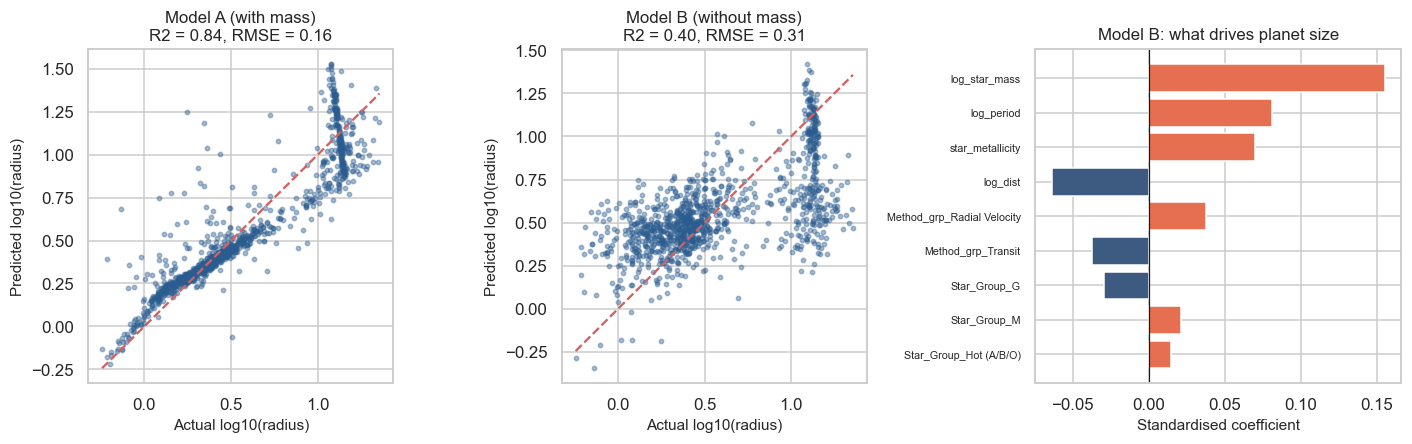

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.2]})
for a_, res_ in [(ax[0], resA), (ax[1], resB)]:
    a_.scatter(res_["yte"], res_["pred"], s=8, alpha=.4, color="#2b5c8f")
    lim = [res_["yte"].min(), res_["yte"].max()]
    a_.plot(lim, lim, "r--", lw=1.5)
    a_.set_xlabel("Actual log10(radius)"); a_.set_ylabel("Predicted log10(radius)")
    a_.set_title(f"{res_['label'].strip()}\nR2 = {res_['r2']:.2f}, RMSE = {res_['rmse']:.2f}")
cs = resB["coef"].reindex(resB["coef"].abs().sort_values().index).tail(9)
ax[2].barh(cs.index, cs.values, color=["#e76f51" if x > 0 else "#3d5a80" for x in cs.values])
ax[2].axvline(0, color="k", lw=.8); ax[2].set_xlabel("Standardised coefficient"); ax[2].set_title("Model B: what drives planet size")
ax[2].tick_params(axis="y", labelsize=7)
finish(fig, "fig8_regression")

# 9. KMeans clustering and PCA

In [20]:
feat = ["log_period", "log_radius", "log_mass", "log_teq", "star_temp_k", "log_star_mass"]
cl = df.dropna(subset=feat).copy()
cl = cl[cl.orbital_period_days < 1e6]
Xc = StandardScaler().fit_transform(cl[feat])
ks = list(range(2, 9))
wcss, sil = [], []
for k in ks:
    km_ = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xc)
    wcss.append(km_.inertia_)
    sil.append(silhouette_score(Xc, km_.labels_))
print(f"Complete cases for clustering: {len(cl)} planets")
print("Silhouette by k:", {k: round(s, 3) for k, s in zip(ks, sil)})
K = ks[int(np.argmax(sil))]            # highest silhouette; change K here if you prefer another value
print("Chosen k (highest silhouette):", K)
km = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(Xc)
cl["Cluster"] = km.labels_ + 1
pca = PCA(n_components=2, random_state=SEED)
X2 = pca.fit_transform(Xc)
ev = pca.explained_variance_ratio_ * 100
print(f"PCA: PC1 = {ev[0]:.1f}%, PC2 = {ev[1]:.1f}% of variance (total {ev.sum():.1f}%)")
prof = cl.groupby("Cluster").agg(planets=("planet_name", "count"), med_radius=("planet_radius_earth", "median"),
                                 med_mass=("planet_mass_earth", "median"), med_period_d=("orbital_period_days", "median"),
                                 med_Teq_K=("equilibrium_temp_k", "median"), med_star_Teff=("star_temp_k", "median"),
                                 med_star_mass=("star_mass_sun", "median"), in_optimistic_HZ=("HZ_optimistic", "sum")).round(2)
print("\nCluster profiles (medians):\n", prof.to_string())
print("\nPlanet types inside each cluster:\n", pd.crosstab(cl.Cluster, cl.planet_type).reindex(columns=PT_ORDER).fillna(0).astype(int).to_string())

Complete cases for clustering: 4500 planets
Silhouette by k: {2: 0.372, 3: 0.373, 4: 0.335, 5: 0.295, 6: 0.299, 7: 0.28, 8: 0.268}
Chosen k (highest silhouette): 3
PCA: PC1 = 46.0%, PC2 = 27.9% of variance (total 73.8%)

Cluster profiles (medians):
          planets  med_radius  med_mass  med_period_d  med_Teq_K  med_star_Teff  med_star_mass  in_optimistic_HZ
Cluster                                                                                                        
1            728        1.92      4.66          7.55      496.9         3810.0           0.55                64
2            907       12.78    293.96          4.15     1345.0         5808.0           1.10                10
3           2865        2.24      5.84         11.13      811.0         5670.0           0.96                39

Planet types inside each cluster:
 planet_type  Sub-Earth  Super-Earth  Mini-Neptune  Neptune-like  Gas Giant  Super-Jupiter
Cluster                                                         

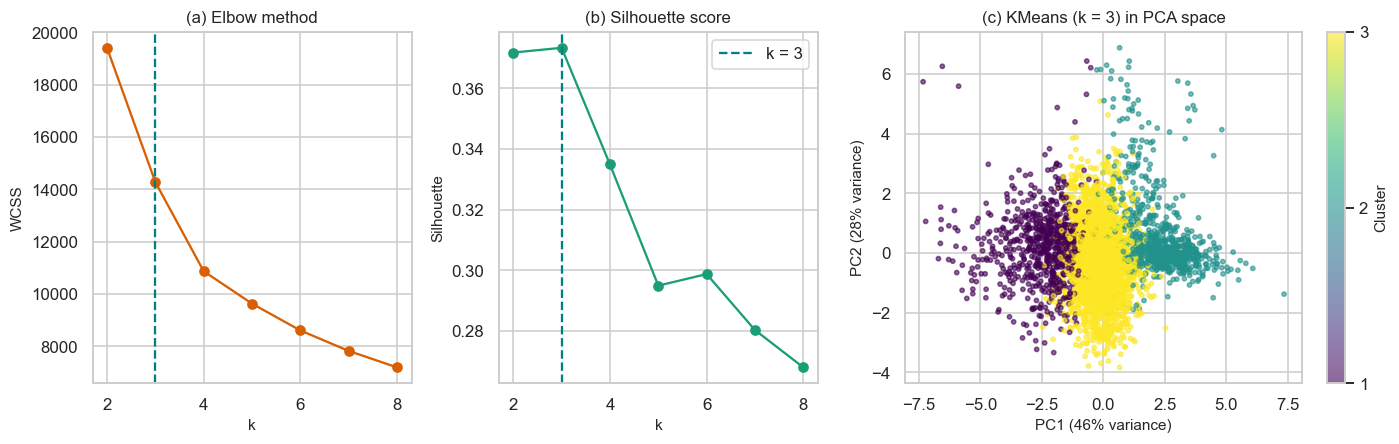

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [0.9, 0.9, 1.4]})
ax[0].plot(ks, wcss, "o-", color="#d95f02"); ax[0].axvline(K, color="teal", ls="--")
ax[0].set_title("(a) Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("WCSS")
ax[1].plot(ks, sil, "o-", color="#1b9e77"); ax[1].axvline(K, color="teal", ls="--", label=f"k = {K}")
ax[1].set_title("(b) Silhouette score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette"); ax[1].legend()
sc_ = ax[2].scatter(X2[:, 0], X2[:, 1], c=cl.Cluster, cmap="viridis", s=8, alpha=.6)
ax[2].set_title(f"(c) KMeans (k = {K}) in PCA space"); ax[2].set_xlabel(f"PC1 ({ev[0]:.0f}% variance)"); ax[2].set_ylabel(f"PC2 ({ev[1]:.0f}% variance)")
plt.colorbar(sc_, ax=ax[2], ticks=range(1, K + 1), label="Cluster")
finish(fig, "fig9_clustering")

# 10. Summary

In [22]:
print("KEY RESULTS")
print(f"  Planets: {len(df)} | host stars: {df.host_star.nunique()} | transit-detected: {(df.discovery_method == 'Transit').mean() * 100:.1f}%")
print(f"  Star types: G {star_tab.loc['G', 'planets']:.0f}, K {star_tab.loc['K', 'planets']:.0f}, F {star_tab.loc['F', 'planets']:.0f}, M {star_tab.loc['M', 'planets']:.0f} planets;"
      f" M-dwarf planets are smaller (median {star_tab.loc['M', 'med_planet_radius']:.1f} vs {star_tab.loc['G', 'med_planet_radius']:.1f} Earth radii for G)")
print(f"  Habitable zone: dataset flag = {int(df.habitable_zone_flag.sum())} planets (Teq 200-400 K); flux-based optimistic HZ = {int(v.HZ_optimistic.sum())}, "
      f"conservative = {int(v.HZ_conservative.sum())}; candidates shortlisted = {len(cand)}")
print(f"  Hypothesis tests: H1 p={p1:.1e}, H2 p={p2:.1e}, H3 p={p3:.1e}, H4 p={p4:.1e}, H5 p={p5:.1e} -> all reject H0 at alpha = {ALPHA}")
print(f"  Regression: R2 = {resA['r2']:.2f} with mass, {resB['r2']:.2f} without; clustering: k = {K}, silhouette = {max(sil):.2f}")
print(f"\nFigures saved in {os.path.abspath(FIG_DIR)}\nCleaned data saved at {os.path.abspath(CLEAN_PATH)}")

KEY RESULTS
  Planets: 6150 | host stars: 4582 | transit-detected: 73.4%
  Star types: G 2669, K 1644, F 1075, M 423 planets; M-dwarf planets are smaller (median 1.9 vs 2.8 Earth radii for G)
  Habitable zone: dataset flag = 403 planets (Teq 200-400 K); flux-based optimistic HZ = 294, conservative = 172; candidates shortlisted = 43
  Hypothesis tests: H1 p=2.4e-93, H2 p=2.2e-45, H3 p=3.3e-37, H4 p=7.0e-21, H5 p=2.9e-16 -> all reject H0 at alpha = 0.05
  Regression: R2 = 0.84 with mass, 0.40 without; clustering: k = 3, silhouette = 0.37

Figures saved in C:\Users\JSNV_C\Downloads\CLEANED\figures
Cleaned data saved at C:\Users\JSNV_C\Downloads\CLEANED\exoplanets_cleaned.csv
